# Module 1 (Chủ Đề Chính): Khôi Phục & Tái Tạo Ảnh Biển Số Xe (Chapters 1, 2, 3, 4, 8 trong `Doc/`)

Notebook này trình bày **chủ đề trọng tâm của đồ án IMP302**: **Khôi phục ảnh suy giảm (Image Degradation, Restoration & Reconstruction - Chapter 3)** kết hợp với đánh giá chất lượng ảnh khách quan (**MSE, SNR, PSNR, SSIM - Chapter 8**):
1. **Mô hình suy giảm tuyến tính bất biến vị trí (Ch. 3.1 & 3.4):** $g(x,y) = h(x,y) * f(x,y) + \eta(x,y)$.
2. **Mở rộng bộ dữ liệu gấp $6\times$ ($115 \rightarrow 690$ ảnh) theo 6 mô hình suy giảm (Ch. 3.2, 3.3, 3.4):** Clean, AWGN ($\sigma=10$), Salt & Pepper ($P=4\%$), Rayleigh/Gamma, Periodic Sinusoidal Interference, và Motion Blur ($L=7,\theta=12^\circ$) + AWGN ($\sigma=7$).
3. **Các bộ lọc không gian, tần số và Wavelet (Ch. 2.2, 3.3, 3.5):** Arithmetic/Geometric/Harmonic/Contraharmonic Mean, Center-Weighted Median, Butterworth Notch Reject Filter, và 2D Haar Wavelet Shrinkage.
4. **Giải chập khôi phục biên (Ch. 3.6, 3.7, 3.8):** So sánh **Inverse Filter**, **Wiener Deconvolution**, và **Constrained Least Squares (CLS) Filtering**.

Dataset Splits (Zero Leakage): Train=80, Val=17, Test=18
6x Multi-Degradation Expanded Dataset: 690 images total
Motion Blur + AWGN Benchmark (115 Plates):
  - Degraded Input          : MSE=190.42 | SNR=19.18 dB | PSNR=25.42 dB | SSIM=0.7244
  - Standard Median (Ch.2)  : MSE=157.11 | SNR=20.06 dB | PSNR=26.30 dB | SSIM=0.8454
  - Weighted Median (Ch.2)  : MSE=156.08 | SNR=20.09 dB | PSNR=26.33 dB | SSIM=0.8390
  - Wavelet DWT (Ch.3.5)    : MSE=164.68 | SNR=19.84 dB | PSNR=26.08 dB | SSIM=0.8210
  - Inverse Filter (Ch.3.8) : MSE=443.27 | SNR=15.45 dB | PSNR=21.69 dB | SSIM=0.3641
  -CLS Filter (Ch.3.7)      : MSE=103.85 | SNR=21.79 dB | PSNR=28.03 dB | SSIM=0.7712
  - Proposed Wavelet+Wiener : MSE=96.61 | SNR=22.09 dB | PSNR=28.34 dB | SSIM=0.7333


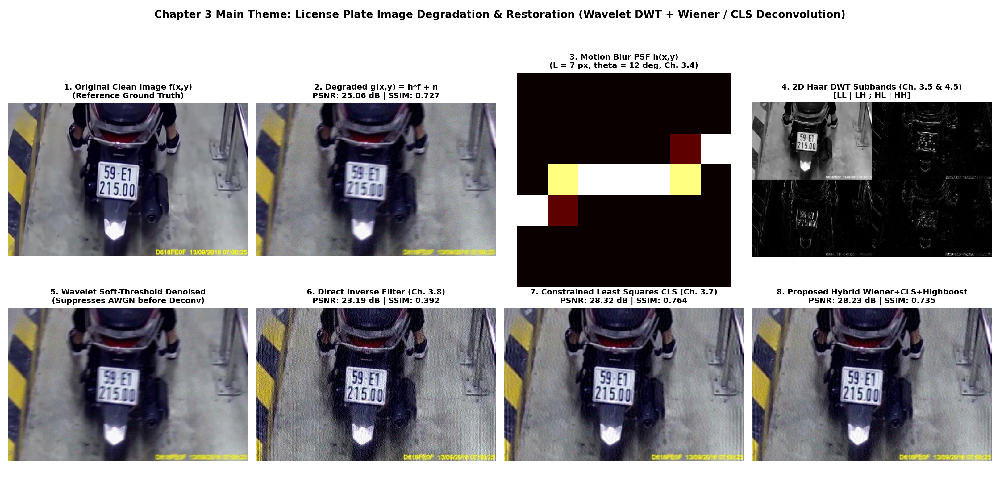

In [1]:
import sys, os, json, cv2, numpy as np
sys.path.append('..')
from src.restoration import (
    synthesize_degraded_image, full_restoration_pipeline,
    inverse_filter_deconvolution, constrained_least_squares_filter,
    wiener_deconvolution, evaluate_quality
)
from src.pipeline import load_dataset, create_dataset_splits

records = load_dataset('../dataset')
splits = create_dataset_splits(records, save_json_path=None)
print(f"Dataset Splits (Zero Leakage): Train={len(splits['train'])}, Val={len(splits['val'])}, Test={len(splits['test'])}")
print(f"6x Multi-Degradation Expanded Dataset: {len(records)*6} images total")

Chapter 3.2 & 3.3 Multi-Noise Restoration Results (PSNR dB):
  - AWGN (sigma=10)      : Degraded=28.25 dB -> Wavelet Proposed=30.60 dB
  - Salt & Pepper (4%)   : Degraded=19.19 dB -> Weighted Median=37.56 dB
  - Rayleigh Skew Noise  : Degraded=32.81 dB -> Harmonic Filter=27.26 dB
  - Periodic Sinusoidal  : Degraded=23.76 dB -> Butterworth Notch=38.30 dB


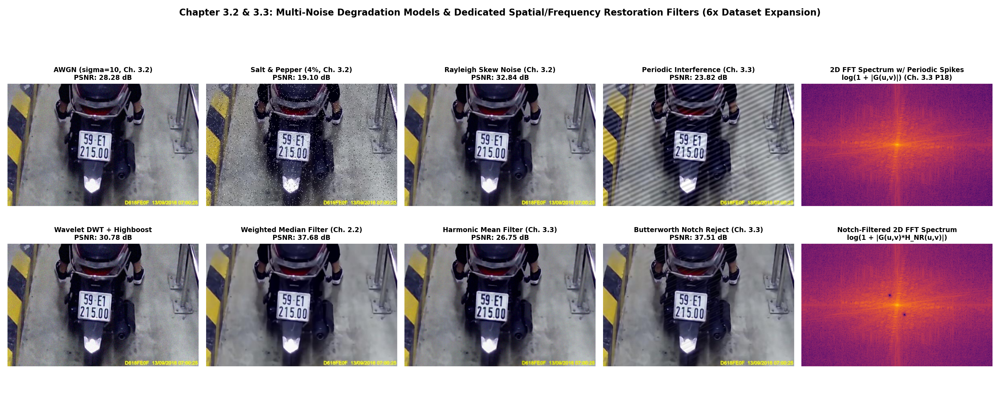

In [2]:
# Trực quan hóa 6 mô hình nhiễu (Ch. 3.2 & 3.3) và khôi phục chuyên biệt (Weighted Median, Harmonic, Notch Reject)
from IPython.display import Image, display
display(Image('../outputs/fig09_multi_degradation_restoration.png'))